# Guess the Type: Wine Notebook
### A very, very simple Machine Learning notebook

## Description
A wine expert can say which **type** a wine is, by looking at its chemical report.
There are 3 types: **0, 1 and 2**.

We will teach the computer to name the type. 
This is called **classification**: the answer is a **type** (a group), not a number.

## The idea of a Decision Tree 
It is like the game of **20 Questions**. The computer asks YES / NO questions.

Example: *Is it a fruit? Yes. Is it red? Yes. Is it round? Yes. It is an apple! *

For wine, the questions look like: *"Is the colour strength more than 3.8?"*
**The computer finds the best questions by itself.**

## Our 7 small steps
1. Bring the tools
2. Get the data
3. Look at the data
4. Split the data
5. Teach the computer
6. Let the computer guess
7. Check the guesses

**Rule of this notebook: one cell = one line of code.** Just press **Shift + Enter** on each cell, one by one.

## Step 1: Bring the tools 
A **library** is a toolbox made by other people. We borrow it, so we do not need to build tools ourselves.

| Tool | What it does (one line) |
|---|---|
| **pandas** | Makes tables, like Excel |
| **matplotlib** | Draws pictures and charts |
| **scikit-learn** | Gives us the data, the model and the score-cards |

We bring the tools one by one. **One cell = one tool.**

**pandas**: `import pandas as pd` means "bring pandas, and call it `pd` for short".

In [1]:
import pandas as pd

**matplotlib**: we use it only to change the size of our tree picture.

In [2]:
import matplotlib.pyplot as plt

**load_wine**: a helper that gets the Wine data for us (178 wines).

In [3]:
from sklearn.datasets import load_wine

**train_test_split**: a helper that cuts the data into two parts (study part and exam part).

In [4]:
from sklearn.model_selection import train_test_split

**DecisionTreeClassifier** is the "brain" (model) that asks YES / NO questions. **plot_tree** draws the tree as a picture.

In [5]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

**Metrics**: score-cards that tell us how good the guesses are.
- `accuracy_score`: how many guesses are right.
- `precision_score`: when I say "type 1", how often am I right?
- `recall_score`: out of all real "type 1" wines, how many did I find?
- `f1_score`: one score that joins precision and recall.
- `ConfusionMatrixDisplay`: draws the score-sheet of right and wrong guesses.

In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

A small setting: show numbers in the normal way (like `0.0001`) and not like `1e-04`.

In [7]:
pd.set_option("display.float_format", "{:.4f}".format)

## Step 2: Get the data 
The data is a table. Each **row** is one wine. Each **column** is one chemical fact about the wine (alcohol, colour, and so on).
The last column, `target`, is the **type** of the wine (0, 1 or 2).

Get the data.

In [8]:
data = load_wine(as_frame=True)

Put the data in a table called `df`.

In [9]:
df = data.frame

Look at the **first 5 wines**.

In [10]:
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.2300,1.7100,2.4300,15.6000,127.0000,2.8000,3.0600,0.2800,2.2900,5.6400,1.0400,3.9200,1065.0000,0
1,13.2000,1.7800,2.1400,11.2000,100.0000,2.6500,2.7600,0.2600,1.2800,4.3800,1.0500,3.4000,1050.0000,0
2,13.1600,2.3600,2.6700,18.6000,101.0000,2.8000,3.2400,0.3000,2.8100,5.6800,1.0300,3.1700,1185.0000,0
3,14.3700,1.9500,2.5000,16.8000,113.0000,3.8500,3.4900,0.2400,2.1800,7.8000,0.8600,3.4500,1480.0000,0
4,13.2400,2.5900,2.8700,21.0000,118.0000,2.8000,2.6900,0.3900,1.8200,4.3200,1.0400,2.9300,735.0000,0


How big is the table? The answer is **(rows, columns)**.

In [11]:
df.shape

(178, 14)

Are there any **empty boxes** (missing values)? `0` means no, the table is full. 

In [12]:
int(df.isnull().sum().sum())

0

Make `X`: the **questions** (the 13 chemical facts). We call these **features**.

In [13]:
X = data.data

Make `y`: the **answer** we want to guess (the type 0, 1 or 2). We call this the **target**.

In [14]:
y = data.target

## Step 3: Look at the data 
We always look first, before we teach the computer.

**How many wines of each type?** Each bar is one type. The bars are not too different, which is good.

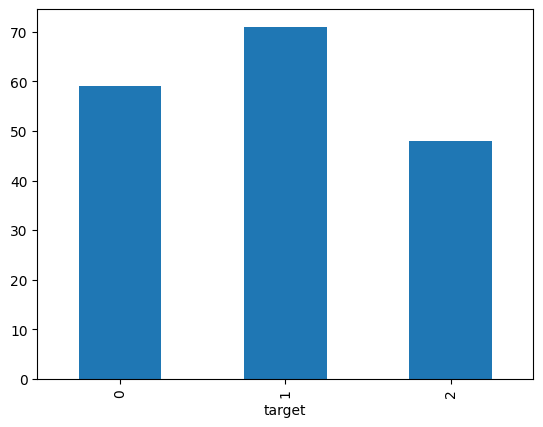

In [15]:
y.value_counts().sort_index().plot.bar();

**Can two facts separate the types?** Each dot is one wine. The colour shows its type.
If the colours make separate groups, the types are **easy to tell apart**.

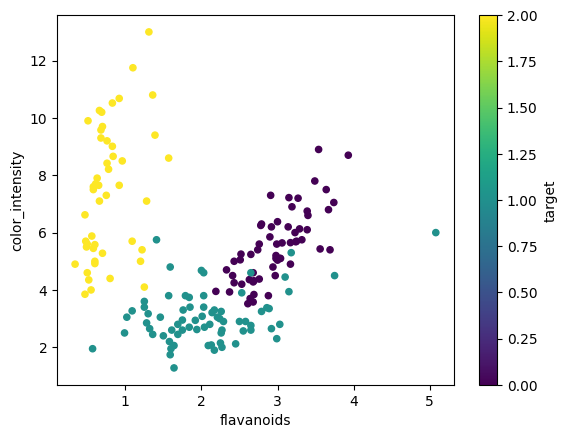

In [16]:
df.plot.scatter(x="flavanoids", y="color_intensity", c="target", colormap="viridis");

## Step 4: Split the data 
A teacher never gives the exam from the same questions the child studied. 

So we cut the wines in two parts:
- **Study part (80%)**: the computer learns from these.
- **Exam part (20%)**: hidden. We use it only to test the computer.

Names we make:
- `X_train`, `y_train` = the study part
- `X_test`, `y_test` = the exam part

(`stratify=y` keeps the same share of each type in both parts. `random_state=42` gives the same cut every time.)

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

How many wines are in the **study part**?

In [18]:
len(X_train)

142

How many wines are in the **exam part**?

In [19]:
len(X_test)

36

## Step 5: Teach the computer 
Two small steps:
1. Make an empty tree. `max_depth=3` means: **ask at most 3 questions in a row**. This keeps the tree small and easy to read.
2. Let it **learn** from the study part. (`fit` means learn.)

Make the tree.

In [20]:
model = DecisionTreeClassifier(max_depth=3, random_state=42)

Teach the tree.

In [21]:
model.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current no

### Let us see the tree it made 
First, make the pictures **big**, so we can read the tree.

In [22]:
plt.rcParams["figure.figsize"] = (18, 8)

Draw the tree. **How to read it:**
- The **first line in a box** is a YES / NO question. **YES goes left. NO goes right.**
- `samples` = how many study wines reached this box.
- `value` = how many of them are type 0, type 1 and type 2.
- The **colour** shows the type. A darker colour means the box is more sure.
- A box at the very bottom has no more questions. That is the final answer.

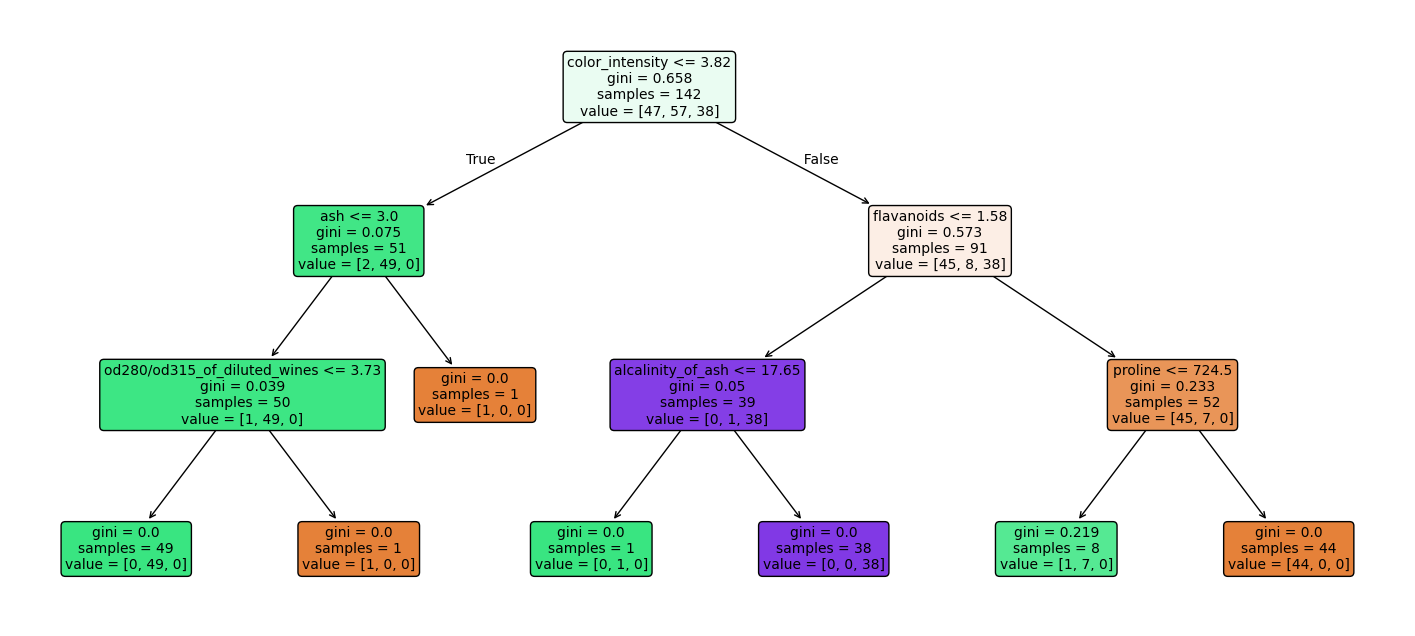

In [23]:
plot_tree(model, feature_names=list(X.columns), filled=True, rounded=True, fontsize=10);

Make the pictures **normal size** again.

In [24]:
plt.rcParams["figure.figsize"] = (6, 4)

## Step 6: Let the computer guess 
Now the tree looks at the **exam wines** (it has never seen them) and names their types.

In [25]:
y_pred = model.predict(X_test)

Put the **real type** and the **guess** side by side in a table.

In [26]:
result = pd.DataFrame({"Real": y_test.values, "Guess": y_pred})

Look at the first 10 wines. Are the guesses the same as the real types?

In [27]:
result.head(10)

,Real,Guess
0,0,0
1,2,1
2,0,0
3,1,1
4,1,1
5,0,0
6,0,0
7,1,1
8,1,1
9,2,2


How many guesses were **wrong**?

In [28]:
int((y_test.values != y_pred).sum())

2

## Step 7: Check the guesses 

### The score-sheet (Confusion Matrix)
This table shows **where the tree was right and where it got confused**.
- **Rows** = the real type. **Columns** = the guessed type.
- The **diagonal** (top-left to bottom-right) = **right** guesses. ✅
- Any number **outside the diagonal** = a mistake. ❌

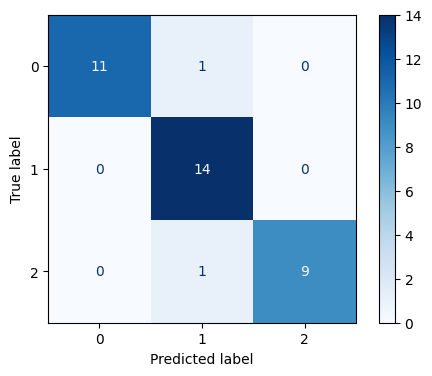

In [29]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues");

### Score 1: Accuracy
**It tells: out of all guesses, how many were right?**
Example: 9 right out of 10 = `0.9`.

**Closer to 1 is better.**

In [30]:
round(accuracy_score(y_test, y_pred), 4)

0.9444

### Score 2: Precision
**It tells: when I say "this is type 1", how often am I really right?**
Example: a fruit seller points at 10 fruits and says "mango". 8 are really mangoes. Precision = `8 / 10 = 0.8`.

(`average="macro"` means: we do this for each of the 3 types and take the average.)

**Closer to 1 is better.**

In [31]:
round(precision_score(y_test, y_pred, average="macro"), 4)

0.9583

### Score 3: Recall
**It tells: out of all the real "type 1" wines, how many did I find?**
Example: there are 16 mangoes in the market. The seller found 8. Recall = `8 / 16 = 0.5`.

**Closer to 1 is better.**

In [32]:
round(recall_score(y_test, y_pred, average="macro"), 4)

0.9389

### Score 4: F1-score
**It tells: one score that joins precision and recall together.**

**Closer to 1 is better.**

In [33]:
round(f1_score(y_test, y_pred, average="macro"), 4)

0.9457

### Is our tree better than a lazy guess? 
A lazy child says the **most common type** for every wine. Our tree should do better than that.

First, the lazy accuracy:

In [34]:
round(float((y_test == y_train.value_counts().idxmax()).mean()), 4)

0.3889

Now our tree's accuracy again. It should be **bigger** than the lazy one above.

In [35]:
round(accuracy_score(y_test, y_pred), 4)

0.9444

### Which facts helped the tree most? 
The longer the bar, the more the fact helped. We show the top 5.

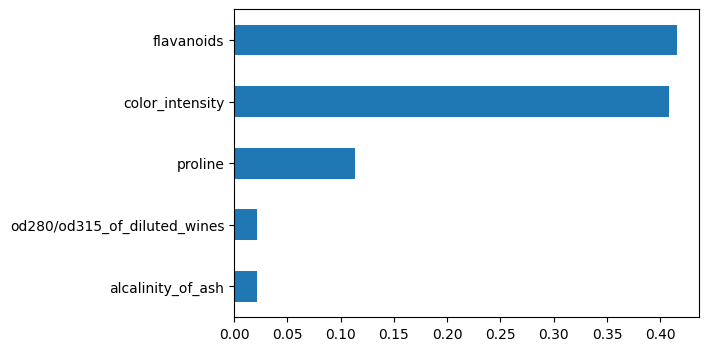

In [36]:
pd.Series(model.feature_importances_, index=X.columns).sort_values().tail(5).plot.barh();

##  What we learned
- We gave the computer chemical facts about wines and it learned to **name the type**.
- Our tree is much better than the lazy guess, so it really learned something.
- The wine types are very different from each other, so even a small tree works very well. Real life data is usually harder.
- The exam part has only 36 wines, so one mistake changes the accuracy by about 3%.

### The 6 steps we followed (almost every ML project follows these)
**Get data → Look → Split → Teach → Guess → Check**